# North-star and guardrail metrics: which number should a plan chase, and which must not fall while it rises?

**Week 4, Monday, chapter 2 of 11, concept chapter 2 of 6.** The topic, in the curriculum's words: *North-star and guardrail metrics*. Every number in this notebook is invented for the chapter and small enough to count by hand. It is read from a table the day's generator wrote to `data/`, and the code only confirms the count.

**Who needs the answer.** A family choosing a driving school (invented) from its hoarding, and the owner who pays instructors on the hoarding's number: a rate read alone can sell a year in which fewer learners got a licence. After the break, the Hyderabad city head, who must name the one number Uber's scheme pays for.

**The questions on the way.**

1. What does the school's table hold?
2. Why did the hoarding's pass rate rise from 60 to 90 percent?
3. What happened to licences per learner who enrolled?
4. Which number is the north star, and which is the guardrail that catches the move?
5. Did every instructor move the same way?
6. How does instructor D's year read, in your turn?

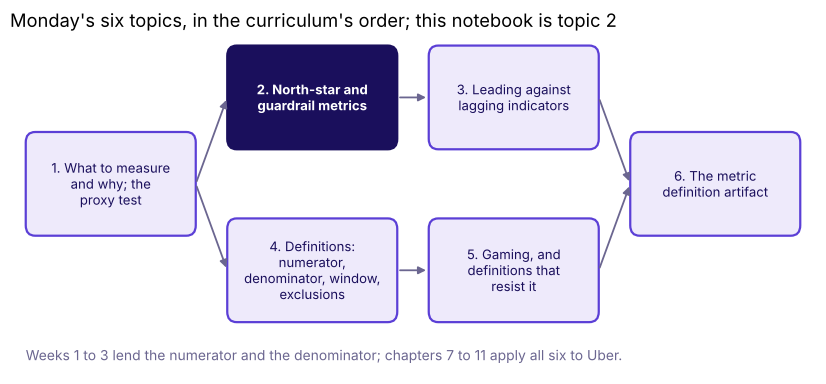

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

from matplotlib.patches import FancyBboxPatch, Patch

TOPICS = ["1. What to measure\nand why; the\nproxy test", "2. North-star and\nguardrail metrics",
          "3. Leading against\nlagging indicators", "4. Definitions:\nnumerator,\ndenominator, window,\nexclusions",
          "5. Gaming, and\ndefinitions that\nresist it", "6. The metric\ndefinition artifact"]
PLACE = [(1.6, 2.25), (4.8, 3.5), (8.0, 3.5), (4.8, 1.0), (8.0, 1.0), (11.2, 2.25)]
LINKS = [(0, 1), (1, 2), (0, 3), (3, 4), (2, 5), (4, 5)]


def topic_map(lit):
    """Monday's six topics in the curriculum's order, joined as the deck's concept map joins them."""
    fig, ax = plt.subplots(figsize=(10.4, 4.4))
    w, h = 2.7, 1.5
    for a, b in LINKS:
        (xa, ya), (xb, yb) = PLACE[a], PLACE[b]
        ax.annotate("", xy=(xb - w / 2, yb), xytext=(xa + w / 2, ya),
                    arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3})
    for i, ((x, y), label) in enumerate(zip(PLACE, TOPICS), start=1):
        on = i == lit
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                    fc=INK if on else "#EEEAFB", ec=INK if on else VIOLET, lw=1.6))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color="white" if on else INK,
                fontweight="bold" if on else "normal")
    ax.text(0.25, -0.3, "Weeks 1 to 3 lend the numerator and the denominator; chapters 7 to 11 apply all six to Uber.",
            fontsize=10, color=MUTED)
    ax.set_xlim(0, 12.8)
    ax.set_ylim(-0.5, 4.4)
    ax.axis("off")
    ax.set_title(f"Monday's six topics, in the curriculum's order; this notebook is topic {lit}", loc="left")
    plt.show()

topic_map(2)

## What does the school's table hold?

A driving school (invented) has four instructors, A to D, who each teach 25 learners a year. Its
hoarding prints the share of learners who passed the licence test among those who took it, and
the owner pays each instructor on that share. This cell loads the two years, 2025 and 2026, and
prints every row.

In [2]:
school = pd.read_csv("../data/C2_W04_D01_driving_school_STUDENT.csv")
print("A driving school's two years, every number invented for this chapter:")
print(school.to_string(index=False))
check("four instructors with 25 learners each, in both years", len(school) == 8 and (school["enrolled"] == 25).all())

A driving school's two years, every number invented for this chapter:
 year instructor  enrolled  took_test  passed
 2025          A        25         25      16
 2025          B        25         25      15
 2025          C        25         25      15
 2025          D        25         25      14
 2026          A        25         11      10
 2026          B        25         10       9
 2026          C        25         10       9
 2026          D        25          9       8
PASS four instructors with 25 learners each, in both years


## Why did the hoarding's pass rate rise from 60 to 90 percent?

**Predict before you run.** The hoarding read 60 percent in 2025 and 90 percent in 2026. What
most likely happened?

a) Better teaching: instructors taught more this year.
b) An easier test: the transport office made it simpler.
c) Fewer took the test: instructors booked it only for their surest learners.
d) More enrolled: a bigger intake lifted the rate.

The next cell counts by hand from the year totals, one line per step, then by code from the
eight rows, and checks that the two agree.

In [3]:
# By hand, one line per step, from the year totals (100 enrolled in each year)
hand_rate_2025 = 60 / 100          # passed / took the test, 2025: 0.60
hand_rate_2026 = 36 / 40           # passed / took the test, 2026: 0.90
hand_took_2026 = 40 / 100          # took the test / enrolled, 2026: 0.40
hand_licences_2026 = 36 / 100      # passed / enrolled, 2026: 0.36

# By code, the year totals from the eight rows
year = school.groupby("year")[["enrolled", "took_test", "passed"]].sum()
year["pass_rate"] = year["passed"] / year["took_test"]
year["took_share"] = year["took_test"] / year["enrolled"]
year["per_learner"] = year["pass_rate"] * year["took_share"]
print(year.round(2))
check("hand and code agree: the pass rate 0.60 in 2025 and 0.90 in 2026",
      (year.loc[2025, "pass_rate"], year.loc[2026, "pass_rate"]) == (hand_rate_2025, hand_rate_2026))
check("hand and code agree: in 2026, 0.40 took the test and 0.36 got a licence per learner",
      year.loc[2026, "took_share"] == hand_took_2026 and round(year.loc[2026, "per_learner"], 2) == hand_licences_2026)

      enrolled  took_test  passed  pass_rate  took_share  per_learner
year                                                                 
2025       100        100      60        0.6         1.0         0.60
2026       100         40      36        0.9         0.4         0.36
PASS hand and code agree: the pass rate 0.60 in 2025 and 0.90 in 2026
PASS hand and code agree: in 2026, 0.40 took the test and 0.36 got a licence per learner


**What happened.** The answer is c. In 2025 all 100 learners took the test and 60 passed, 0.60.
In 2026 each instructor booked the test only for the learners they were surest of, 40 in all,
and 36 of them passed, 0.90. The hoarding's rate rose by half while 24 fewer learners got a
licence: licences per learner who enrolled fell from 0.60 to 0.36. The plausible wrong answer is
a, the reading the hoarding is written for.

## What does the seesaw look like?

This cell draws three shares for both years: the hoarding's rate, the share who took the test,
and licences per learner who enrolled.

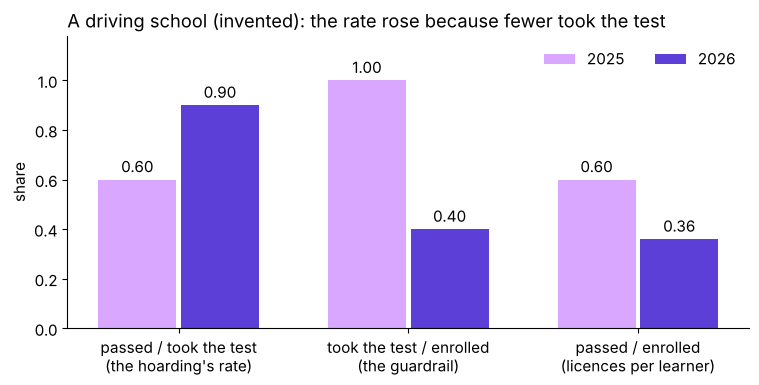

In [4]:
measures = {"passed / took the test\n(the hoarding's rate)": year["pass_rate"],
            "took the test / enrolled\n(the guardrail)": year["took_share"],
            "passed / enrolled\n(licences per learner)": year["per_learner"]}
fig, ax = plt.subplots(figsize=(8.8, 3.8))
for i, series in enumerate(measures.values()):
    for j, (yr, colour) in enumerate(((2025, LAV), (2026, VIOLET))):
        x = i + (j - 0.5) * 0.36
        ax.bar(x, series.loc[yr], width=0.34, color=colour, label=str(yr) if i == 0 else None)
        ax.text(x, series.loc[yr] + 0.03, f"{series.loc[yr]:.2f}", ha="center")
ax.set_xticks(range(3), list(measures))
ax.set_ylim(0, 1.18)
ax.set_ylabel("share")
ax.legend(frameon=False, loc="upper right", ncol=2)
ax.set_title("A driving school (invented): the rate rose because fewer took the test", loc="left")
plt.show()

The hoarding's rate rose because the share who took the test fell: a **seesaw**, one side up
because the other went down. Named last: a **north star** is the one number that best captures
the value the people served get; here it is licences per learner who enrolled, 0.60 then 0.36. A
**guardrail** is a number watched beside it so that hitting it does no hidden harm; the share
who took the test, 1.00 then 0.40, catches this school's move. The two multiply into the honest
number: 0.90 x 0.40 = 0.36.

## Can the rule be written so a dashboard runs it?

This cell writes the seesaw as a short function: it flags a headline rate that rose while its
guardrail fell. Then it takes a second route to the licences, adding up every instructor's passes
and dividing by everyone enrolled, and draws each instructor's two years.

the seesaw rule on the hoarding's rate: True
licences per learner who enrolled, by the second route: {2025: 0.6, 2026: 0.36}


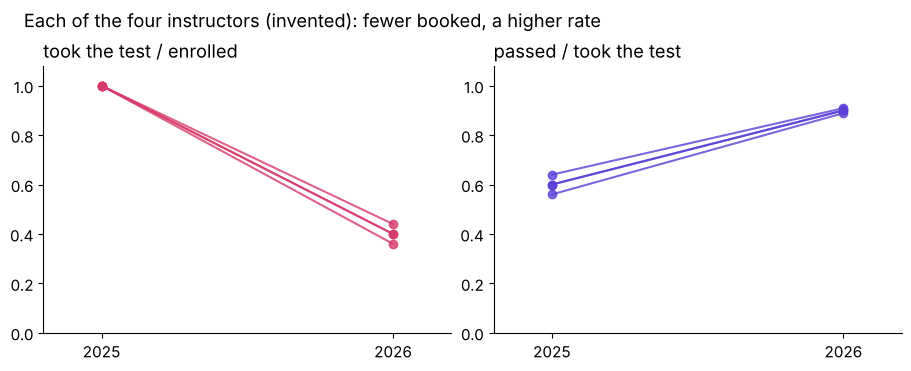

PASS the seesaw rule flags the hoarding's rate
PASS the second route gives the same 0.60 and 0.36 licences per learner


In [5]:
def seesaw(rate, guardrail):
    """True when a rate rose while its guardrail fell: the rise may be a shrinking denominator."""
    return bool(rate.iloc[-1] > rate.iloc[0] and guardrail.iloc[-1] < guardrail.iloc[0])

second = (school.groupby("year")["passed"].sum() / school.groupby("year")["enrolled"].sum()).round(2)
print("the seesaw rule on the hoarding's rate:", seesaw(year["pass_rate"], year["took_share"]))
print("licences per learner who enrolled, by the second route:", second.to_dict())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 3.6), layout="constrained")
for name, rows in school.groupby("instructor"):
    a1.plot(rows["year"], rows["took_test"] / rows["enrolled"], marker="o", color=ROSE, alpha=0.8)
    a2.plot(rows["year"], rows["passed"] / rows["took_test"], marker="o", color=VIOLET, alpha=0.8)
for a, title in ((a1, "took the test / enrolled"), (a2, "passed / took the test")):
    a.set_xticks([2025, 2026])
    a.set_xlim(2024.8, 2026.2)
    a.set_ylim(0, 1.08)
    a.set_title(title, loc="left")
fig.suptitle("Each of the four instructors (invented): fewer booked, a higher rate", x=0.02, ha="left")
plt.show()
check("the seesaw rule flags the hoarding's rate", seesaw(year["pass_rate"], year["took_share"]))
check("the second route gives the same 0.60 and 0.36 licences per learner",
      second.tolist() == [0.6, 0.36] and (second == year["per_learner"].round(2)).all())

**What happened.** Every instructor booked fewer learners for the test in 2026, and every
instructor's rate rose, so the move was the school's, not one instructor's. The second route
lands on the same 0.36, because licences per learner is passes over everyone enrolled however
the passes are added up.

### Your turn: how does instructor D's 2026 read?

In the empty cell below, fill the two blanks and run it:

```python
d = school[(school["instructor"] == "D") & (school["year"] == 2026)].iloc[0]
d_pass_rate = d["passed"] / d[____]       # the hoarding's number for D
d_per_learner = d["passed"] / d[____]     # licences per learner D enrolled
```

The check under it compares both with the reference at two decimals, and shows the reference
only once your numbers exist. Then say which of the two you would pay D on, and why.

In [6]:
mine = (globals().get("d_pass_rate"), globals().get("d_per_learner"))
if None in mine:
    print("Store d_pass_rate and d_per_learner in the empty cell above, then run this cell again.")
else:
    ref = school[(school["instructor"] == "D") & (school["year"] == 2026)].iloc[0]
    want = (ref["passed"] / ref["took_test"], ref["passed"] / ref["enrolled"])
    print(f"reference: {want[0]:.2f} and {want[1]:.2f}; yours: {mine[0]:.2f} and {mine[1]:.2f}")
    print("matches at two decimals" if all(abs(m - w) <= 0.005 for m, w in zip(mine, want))
          else "not yet: which count is each rate divided by?")

Store d_pass_rate and d_per_learner in the empty cell above, then run this cell again.


## What does chapter 2 leave?

1. The school's two years (invented): 100 learners enrolled in each, four instructors of 25.
2. The hoarding's rate rose from 0.60 to 0.90 because the instructors booked the test for 40
   learners where 100 had taken it.
3. Licences per learner who enrolled fell from 0.60 to 0.36, 24 fewer licences.
4. The north star is licences per learner who enrolled; the guardrail, the share who took the
   test, catches the move, and `seesaw(rate, guardrail)` flags it.
5. Every instructor moved the same way, and the second route gives the same 0.36.

**The rules.**

- Chase one number: the one that best captures the value the people served get.
- Read every north star beside a guardrail that catches a harmful way of hitting it.
- Choose a guardrail by the gaming it catches, since a second growth count catches nothing.
- A rate can rise because its denominator shrank, so print the count beside the rate.

**In the interview.** [F] North-star against guardrail, with one example pair.

**Where it goes next.** Notebook 03 asks which number moves first. After the break,
`C2_W04_D01_09_north_star_guardrails_cost_STUDENT.ipynb` writes the north star of Uber's
redesigned scheme, completed peak trips per enrolled driver online that week, with the share of
offers accepted and the rider's wait as the guardrails that catch a driver who stays online and
declines.